<a href="https://colab.research.google.com/github/Sanika515/AIML/blob/main/5_Facial_Emotion_Recognition_using_CNN_Build_a_convolutional_neural_network_(CNN)_model_to_detect_emotions_from_facial_images_(happy%2C_sad%2C_angry%2C_etc_)_%5BDataset_FER_2013_(Facial_Emotion_Recognition_dataset).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install kagglehub
import os, kagglehub
path = kagglehub.dataset_download('msambare/fer2013')
print(path, os.listdir(path))

Using Colab cache for faster access to the 'fer2013' dataset.
/kaggle/input/fer2013 ['test', 'train']


/kaggle/input/fer2013/train /kaggle/input/fer2013/test
Found 28709 files belonging to 7 classes.
Using 25839 files for training.
Found 28709 files belonging to 7 classes.
Using 2870 files for validation.
Found 7178 files belonging to 7 classes.
['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


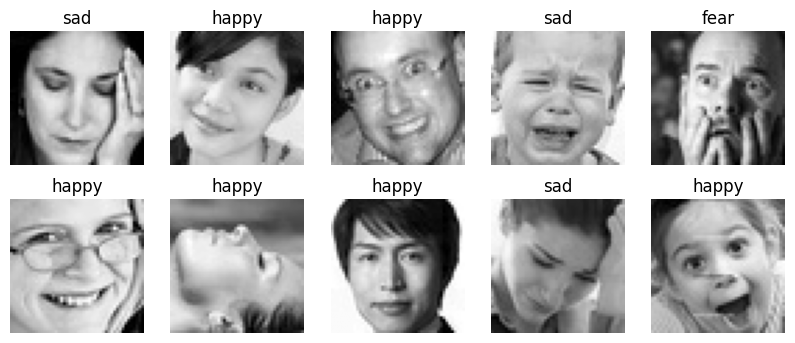

In [ ]:
import os, numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

# folders: <path>/train/<emotion>/*.jpg and <path>/test/<emotion>/*.jpg
def find_dir(p, name):
    for root, dirs, _ in os.walk(p):
        if name in dirs: return os.path.join(root, name)
train_dir, test_dir = find_dir(path, 'train'), find_dir(path, 'test')
print(train_dir, test_dir)

IMG = (48, 48); BATCH = 64
train_ds = keras.utils.image_dataset_from_directory(train_dir, color_mode='grayscale', image_size=IMG, batch_size=BATCH,
                                                    validation_split=0.1, subset='training', seed=42)
val_ds   = keras.utils.image_dataset_from_directory(train_dir, color_mode='grayscale', image_size=IMG, batch_size=BATCH,
                                                    validation_split=0.1, subset='validation', seed=42)
test_ds  = keras.utils.image_dataset_from_directory(test_dir, color_mode='grayscale', image_size=IMG, batch_size=BATCH, shuffle=False)
class_names = train_ds.class_names
print(class_names)

# show samples
imgs, labs = next(iter(train_ds))
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1); plt.imshow(imgs[i].numpy().squeeze(), cmap='gray'); plt.title(class_names[labs[i]]); plt.axis('off')
plt.show()

In [ ]:
# CNN model: 3 conv blocks + classifier
model = keras.Sequential([
    layers.Input(shape=(48, 48, 1)),
    layers.Rescaling(1./255),
    layers.RandomFlip('horizontal'),
    layers.Conv2D(32, 3, padding='same', activation='relu'), layers.BatchNormalization(), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'), layers.BatchNormalization(), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding='same', activation='relu'), layers.BatchNormalization(), layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()
history = model.fit(train_ds, validation_data=val_ds, epochs=15)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 684,423 (2.61 MB)

 Trainable params: 683,975 (2.61 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/15
404/404 ━━━━━━━━━━━━━━━━━━━━ 126s 307ms/step - accuracy: 0.2780 - loss: 1.8246 - val_accuracy: 0.2523 - val_loss: 1.7754
Epoch 2/15
404/404 ━━━━━━━━━━━━━━━━━━━━ 121s 257ms/step - accuracy: 0.3264 - loss: 1.6457 - val_accuracy: 0.3728 - val_loss: 1.6037
Epoch 3/15
404/404 ━━━━━━━━━━━━━━━━━━━━ 104s 257ms/step - accuracy: 0.3487 - loss: 1.5901 - val_accuracy: 0.3369 - val_loss: 1.6302
Epoch 4/15
404/404 ━━━━━━━━━━━━━━━━━━━━ 143s 260ms/step - accuracy: 0.3668 - loss: 1.5523 - val_accuracy: 0.3864 - val_loss: 1.5259
Epoch 5/15
404/404 ━━━━━━━━━━━━━━━━━━━━ 140s 255ms/step - accuracy: 0.3742 - loss: 1.5325 - val_accuracy: 0.4157 - val_loss: 1.4883
Epoch 6/15
404/404 ━━━━━━━━━━━━━━━━━━━━ 141s 254ms/step - accuracy: 0.3846 - loss: 1.5081 - val_accuracy: 0.4348 - val_loss: 1.4539
Epoch 7/15
404/404 ━━━━━━━━━━━━━━━━━━━━ 105s 261ms/step - accuracy: 0.3920 - loss: 1.4909 - val_accuracy: 0.4436 - val_loss: 1.4070
Epoch 8/15
404/404 ━━━━━━━━━━━━━━━━━━━━ 137s 247ms/step - accuracy: 0.4182 -

Test accuracy: 51.91%
              precision    recall  f1-score   support

       angry       0.48      0.27      0.35       958
     disgust       0.00      0.00      0.00       111
        fear       0.35      0.15      0.21      1024
       happy       0.78      0.78      0.78      1774
     neutral       0.41      0.68      0.51      1233
         sad       0.35      0.51      0.42      1247
    surprise       0.81      0.53      0.64       831

    accuracy                           0.52      7178
   macro avg       0.45      0.42      0.42      7178
weighted avg       0.53      0.52      0.50      7178



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


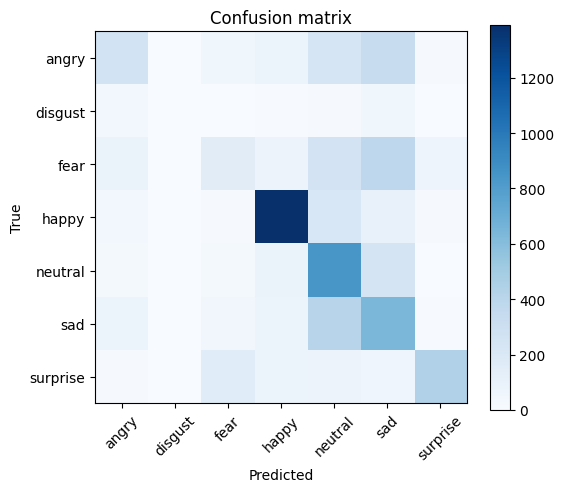

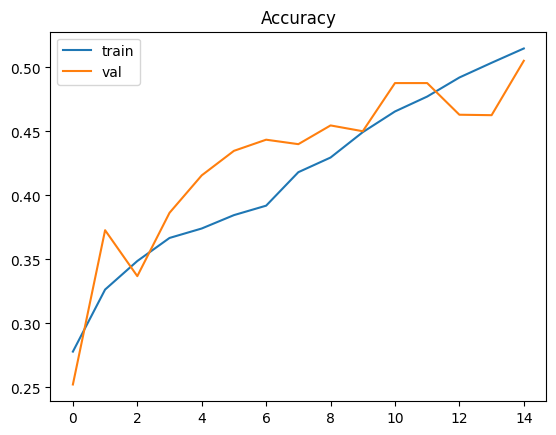

In [ ]:
# Evaluate on the test set
loss, acc = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy: {acc*100:.2f}%")          # FER-2013 is hard: about 55-62% is normal for a simple CNN

y_true, y_pred = [], []
for x, y in test_ds:
    y_true += list(y.numpy()); y_pred += list(np.argmax(model.predict(x, verbose=0), axis=1))
print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5)); plt.imshow(cm, cmap='Blues'); plt.colorbar()
plt.xticks(range(len(class_names)), class_names, rotation=45); plt.yticks(range(len(class_names)), class_names)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion matrix'); plt.show()

plt.plot(history.history['accuracy'], label='train'); plt.plot(history.history['val_accuracy'], label='val')
plt.legend(); plt.title('Accuracy'); plt.show()

In [ ]:
problem statement (as in your list): "Implement a CNN for facial emotion recognition using the FER-2013 dataset."

1. What is the problem?

We give the computer a photo of a face and it must say which emotion it shows. FER-2013 has about 35,000 small face pictures (48 × 48 pixels, black and white) in 7 emotions: angry, disgust, fear, happy, neutral, sad, surprise.

2. What is the solution?

We use a CNN, like Problem 1, but with a bigger model. Facial expressions are made of small patterns: the curve of the mouth, the raised eyebrows, wide eyes. Convolution filters learn to find those patterns. The deeper layers then combine them into a whole expression.

"The early layers find edges, the middle layers find parts like eyes and mouth, and the last layers decide the emotion."

################## CODE ##########################
. The code, explained

Step 1: Download the data

python
import kagglehub
path = kagglehub.dataset_download('msambare/fer2013')

It downloads the dataset from Kaggle. The data is arranged as train/<emotion>/ and test/<emotion>/ folders. Each folder name is the label.

Step 2: Load images

python
train_ds = keras.utils.image_dataset_from_directory(train_dir, color_mode='grayscale',
              image_size=(48,48), batch_size=64, validation_split=0.1, subset='training', seed=42)
val_ds = ... subset='validation' ...
test_ds = keras.utils.image_dataset_from_directory(test_dir, ..., shuffle=False)
class_names = train_ds.class_names
It reads every image from the folders and uses the folder name as the label.
color_mode='grayscale' gives 1 channel.
10% of the train folder is kept as validation. The separate test folder is for the final check.
The same seed for both subsets means they don't overlap.

Step 3: Build the CNN

python
model = keras.Sequential([
    layers.Input(shape=(48,48,1)),
    layers.Rescaling(1./255),
    layers.RandomFlip('horizontal'),
    layers.Conv2D(32, 3, padding='same', activation='relu'), layers.BatchNormalization(), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'), layers.BatchNormalization(), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding='same', activation='relu'), layers.BatchNormalization(), layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation='softmax')
])

The number of output neurons equals the number of emotions (7).

Step 4: Train

python
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_ds, validation_data=val_ds, epochs=15)

Step 5: Evaluate

python
loss, acc = model.evaluate(test_ds)
print(classification_report(y_true, y_pred, target_names=class_names))
cm = confusion_matrix(y_true, y_pred)
evaluate gives the test accuracy.
The classification report gives precision, recall and F1 for each emotion.
The confusion matrix shows which emotions get mixed up.

Step 6: Predict. It shows 10 test faces with predicted (P:) and true (T:) emotions.

4. The output you will see
Found ~28,700 files belonging to 7 classes for training, and about 7,100 for the test folder.
A grid of 10 sample faces with their emotion names.
Model summary, with the Flatten output of 4608 and the biggest parameter count in the Dense 128 layer (589,952).
Training log of 15 epochs. Training accuracy climbs towards 65–70%.
Test accuracy of about 55–62%. I haven't run it on the real dataset, so go by your own number.
The classification report: happy and surprise score best, and disgust and fear score worst.
A confusion matrix and an accuracy graph.
10 test faces with predictions.
5. Why is the accuracy only about 60%? (the examiner will ask)

This is normal for FER-2013, and it is a good thing to explain well:

The images are tiny (48×48), blurry and taken "in the wild".
Some labels are wrong or unclear. Even humans only agree on these labels about 65% of the time.
Class imbalance: "happy" has about 8,000 images, but "disgust" has only about 500, so the model rarely learns disgust.
Expressions like fear and sad look alike, so they get confused.
Better accuracy (around 70%) needs bigger models or transfer learning.

"FER-2013 is a hard dataset because of noisy labels and class imbalance, so 55–62% is a normal accuracy for a simple CNN."

###########BLOCK#########

          START
            |
            v
      Load FER-2013 Dataset
            |
            v
      Preprocess Images
       (48 × 48 Gray)
            |
            v
       Split Dataset
     Train / Validation
            |
            v
        Build CNN Model
            |
            v
       Convolution + ReLU
            |
            v
         Max Pooling
            |
            v
       Repeat CNN Blocks
            |
            v
          Flatten
            |
            v
       Dense + Dropout
            |
            v
       Softmax (7 Classes)
            |
            v
        Train the Model
            |
            v
       Evaluate Accuracy
            |
            v
      Predict Emotions
            |
            v
           STOP



###############QUE#########
. Questions the examiner may ask
What is FER-2013? Facial Expression Recognition 2013: about 35,000 grayscale 48×48 faces with 7 emotion labels, from a Kaggle challenge.
What is Batch Normalization? It normalises each layer's outputs for every mini-batch, which gives faster and more stable training.
Why Dropout 0.5? The dense layer has about 590,000 parameters and overfits easily. Dropout switches off half the neurons randomly.
What is a confusion matrix? A table of true class against predicted class. The diagonal is correct, and the other cells show which emotions get confused.
Precision, recall, F1? Precision = TP/(TP+FP), recall = TP/(TP+FN), F1 balances both.
Which augmentation suits faces? Horizontal flip, small rotation, zoom and brightness change, but not vertical flip.
How would you do real-time emotion detection? Detect the face with a Haar cascade or MTCNN, crop and resize it to 48×48 grayscale, and feed it to this CNN.
How do you handle class imbalance? Class weights, oversampling the rare classes, or more augmentation for them.
